# Problema 5 - Segmentação de Clientes com k-Means

[![Abrir no Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/FredGregorio/Disciplina-sistemas-inteligentes-2026.2/blob/main/Primeira%20Unidade/Projetos/05-kmeans-wholesale-customers/src/problema5.ipynb)

## 1. Importando as bibliotecas e carregando os dados

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score
from sklearn.decomposition import PCA

plt.rcParams['figure.figsize'] = (8, 4)

In [2]:
if os.path.exists("../data/wholesale_customers.csv"):
    caminho_dados = "../data/wholesale_customers.csv"
    pasta_resultados = "../resultados"
else:
    caminho_dados = "https://raw.githubusercontent.com/FredGregorio/Disciplina-sistemas-inteligentes-2026.2/main/Primeira%20Unidade/Projetos/05-kmeans-wholesale-customers/data/wholesale_customers.csv"
    pasta_resultados = "resultados"

os.makedirs(pasta_resultados, exist_ok=True)

df = pd.read_csv(caminho_dados)
df.head()

,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
0,2,3,12669,9656,7561,214,2674,1338
1,2,3,7057,9810,9568,1762,3293,1776
2,2,3,6353,8808,7684,2405,3516,7844
3,1,3,13265,1196,4221,6404,507,1788
4,2,3,22615,5410,7198,3915,1777,5185


In [3]:
print(f"Quantidade de clientes = {df.shape[0]}")
print(f"Valores ausentes = {df.isna().sum().sum()}")

Quantidade de clientes = 440
Valores ausentes = 0


## 2. Tarefa 1 - Preparação dos dados

### 2.1 Separando `Channel` e `Region`

In [4]:
canal = df["Channel"].map({1: "Horeca", 2: "Retail"})
regiao = df["Region"].map({1: "Lisboa", 2: "Porto", 3: "Outras"})

categorias = ["Fresh", "Milk", "Grocery", "Frozen", "Detergents_Paper", "Delicassen"]
gastos = df[categorias]

print(canal.value_counts().to_dict())
print(regiao.value_counts().to_dict())

{'Horeca': 298, 'Retail': 142}
{'Outras': 316, 'Lisboa': 77, 'Porto': 47}


### 2.2 Estatísticas de cada categoria de gasto

In [5]:
estatisticas = pd.DataFrame({
    "média": gastos.mean(),
    "mediana": gastos.median(),
    "desvio padrão": gastos.std(),
    "mínimo": gastos.min(),
    "máximo": gastos.max(),
}).round(0)
estatisticas

,média,mediana,desvio padrão,mínimo,máximo
Fresh,12000.0,8504.0,12647.0,3,112151
Milk,5796.0,3627.0,7380.0,55,73498
Grocery,7951.0,4756.0,9503.0,3,92780
Frozen,3072.0,1526.0,4855.0,25,60869
Detergents_Paper,2881.0,816.0,4768.0,3,40827
Delicassen,1525.0,966.0,2820.0,3,47943


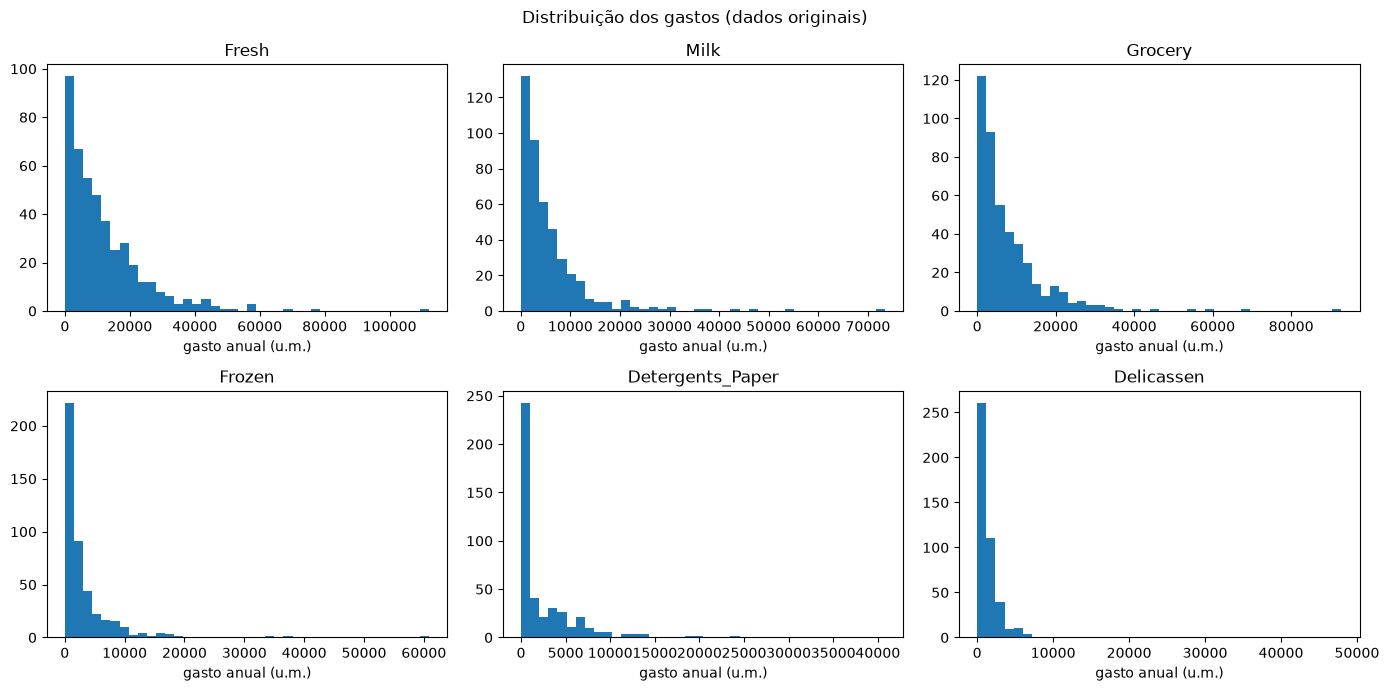

In [6]:
fig, eixos = plt.subplots(2, 3, figsize=(14, 7))
for eixo, cat in zip(eixos.ravel(), categorias):
    eixo.hist(gastos[cat], bins=40)
    eixo.set_title(cat)
    eixo.set_xlabel("gasto anual (u.m.)")
plt.suptitle("Distribuição dos gastos (dados originais)")
plt.tight_layout()
plt.savefig(f"{pasta_resultados}/histogramas_originais.png", dpi=150)
plt.show()

### 2.3 Transformação logarítmica: $x' = \log(1 + x)$

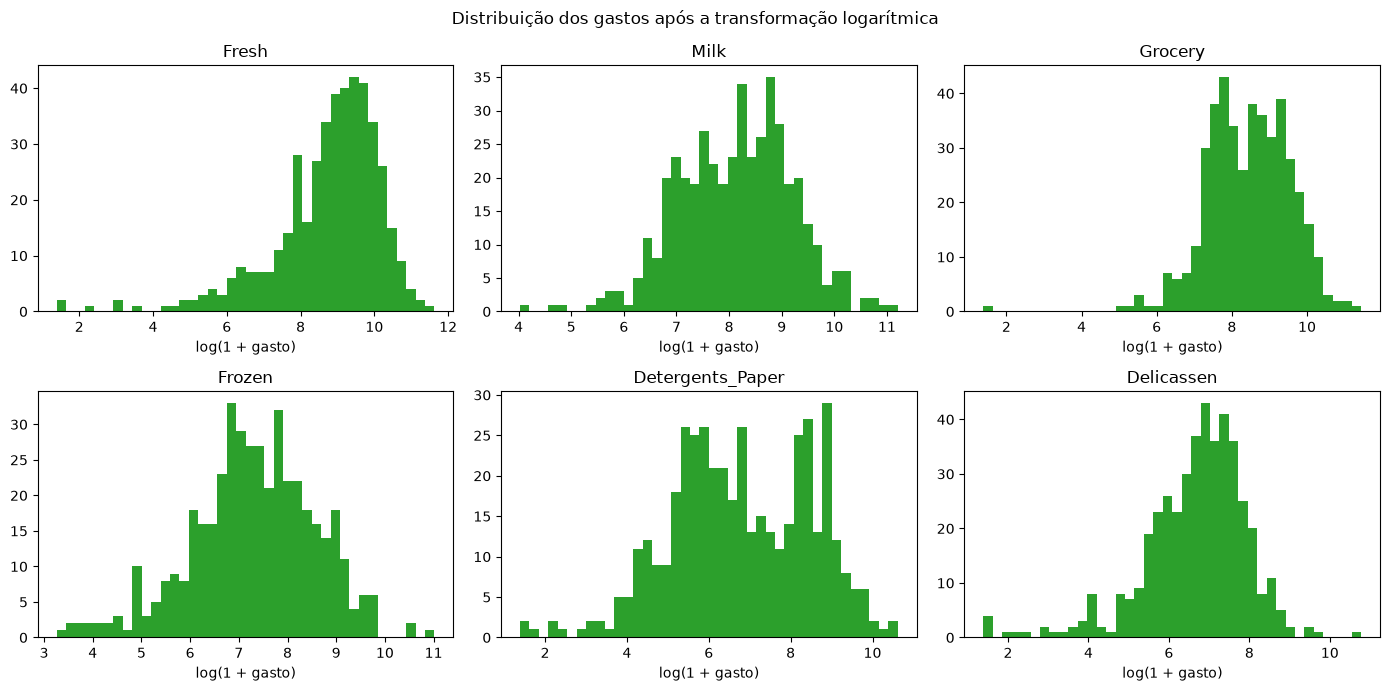

In [7]:
gastos_log = np.log1p(gastos)

fig, eixos = plt.subplots(2, 3, figsize=(14, 7))
for eixo, cat in zip(eixos.ravel(), categorias):
    eixo.hist(gastos_log[cat], bins=40, color="tab:green")
    eixo.set_title(cat)
    eixo.set_xlabel("log(1 + gasto)")
plt.suptitle("Distribuição dos gastos após a transformação logarítmica")
plt.tight_layout()
plt.savefig(f"{pasta_resultados}/histogramas_log.png", dpi=150)
plt.show()

### 2.4 Padronização (z-score)

In [8]:
scaler = StandardScaler()
X = scaler.fit_transform(gastos_log)

print("Médias após padronizar:        ", X.mean(axis=0).round(4))
print("Desvios padrão após padronizar:", X.std(axis=0).round(4))

Médias após padronizar:         [ 0. -0. -0.  0. -0. -0.]
Desvios padrão após padronizar: [1. 1. 1. 1. 1. 1.]


### 2.5 Matriz de correlação entre as seis categorias

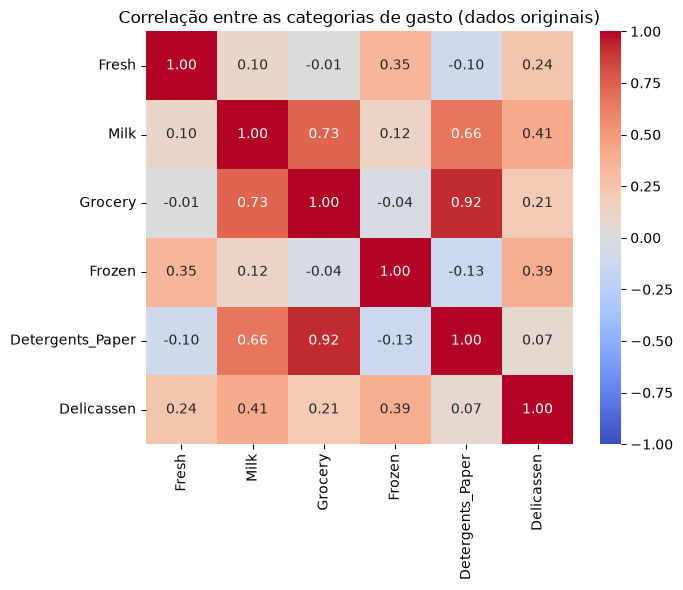

Grocery x Detergents_Paper (dados originais): 0.925
Grocery x Detergents_Paper (após o log):      0.797


In [9]:
corr = gastos.corr()

plt.figure(figsize=(7, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlação entre as categorias de gasto (dados originais)")
plt.tight_layout()
plt.savefig(f"{pasta_resultados}/correlacao.png", dpi=150)
plt.show()

print(f"Grocery x Detergents_Paper (dados originais): {corr.loc['Grocery', 'Detergents_Paper']:.3f}")
print(f"Grocery x Detergents_Paper (após o log):      {gastos_log.corr().loc['Grocery', 'Detergents_Paper']:.3f}")

## 3. Tarefa 3 - Escolha do número de grupos

In [10]:
valores_k = range(2, 11)
inercias = []
silhuetas = []

for k in valores_k:
    km = KMeans(n_clusters=k, n_init=10, random_state=42)
    rotulos = km.fit_predict(X)
    inercias.append(km.inertia_)
    silhuetas.append(silhouette_score(X, rotulos))
    print(f"k = {k:2d} | inércia = {km.inertia_:8.1f} | silhueta = {silhuetas[-1]:.4f}")

k =  2 | inércia =   1844.1 | silhueta = 0.2903
k =  3 | inércia =   1553.4 | silhueta = 0.2594


k =  4 | inércia =   1386.9 | silhueta = 0.1885
k =  5 | inércia =   1266.1 | silhueta = 0.1916


k =  6 | inércia =   1174.8 | silhueta = 0.2009
k =  7 | inércia =   1086.4 | silhueta = 0.1958
k =  8 | inércia =   1028.5 | silhueta = 0.1852


k =  9 | inércia =    973.1 | silhueta = 0.1965
k = 10 | inércia =    932.0 | silhueta = 0.1905


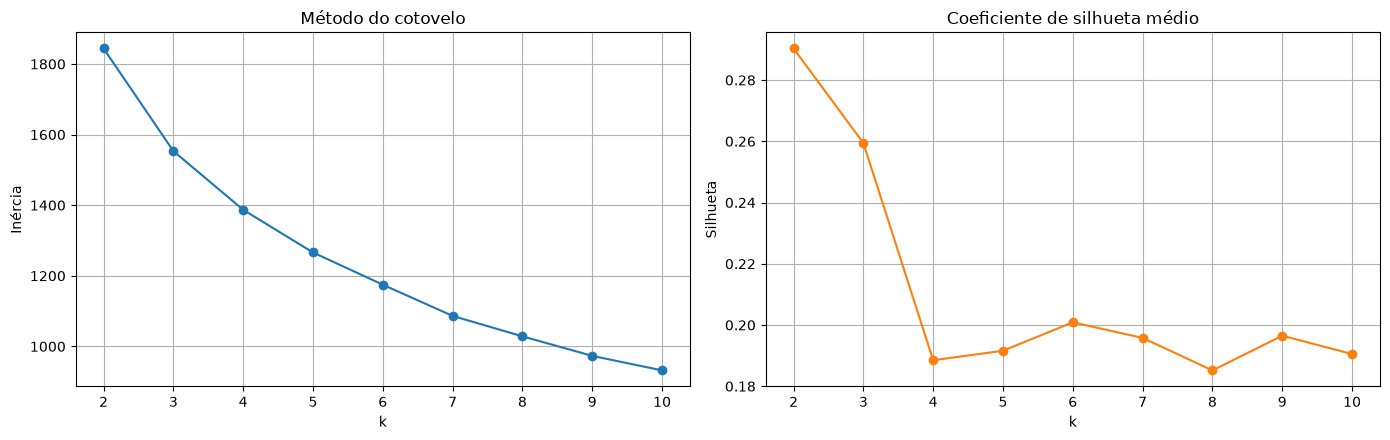

In [11]:
fig, eixos = plt.subplots(1, 2, figsize=(14, 4.5))

eixos[0].plot(list(valores_k), inercias, marker='o')
eixos[0].set_title("Método do cotovelo")
eixos[0].set_xlabel("k")
eixos[0].set_ylabel("Inércia")
eixos[0].grid()

eixos[1].plot(list(valores_k), silhuetas, marker='o', color="tab:orange")
eixos[1].set_title("Coeficiente de silhueta médio")
eixos[1].set_xlabel("k")
eixos[1].set_ylabel("Silhueta")
eixos[1].grid()

plt.tight_layout()
plt.savefig(f"{pasta_resultados}/cotovelo_silhueta.png", dpi=150)
plt.show()

In [12]:
# Quanto a inércia diminui a cada novo grupo
quedas = -np.diff(inercias)
for k, q in zip(list(valores_k)[1:], quedas):
    print(f"de k = {k-1} para k = {k}: a inércia cai {q:6.1f}")

de k = 2 para k = 3: a inércia cai  290.6
de k = 3 para k = 4: a inércia cai  166.6
de k = 4 para k = 5: a inércia cai  120.7
de k = 5 para k = 6: a inércia cai   91.4
de k = 6 para k = 7: a inércia cai   88.4
de k = 7 para k = 8: a inércia cai   57.9
de k = 8 para k = 9: a inércia cai   55.3
de k = 9 para k = 10: a inércia cai   41.1


In [13]:
K = 3

## 4. Tarefa 4 - Inicialização e convergência

In [14]:
resultados = []
for semente in range(10):
    for metodo in ["random", "k-means++"]:
        km = KMeans(n_clusters=K, init=metodo, n_init=1, random_state=semente)
        km.fit(X)
        resultados.append({"semente": semente, "init": metodo, "inércia": km.inertia_})

tabela_init = pd.DataFrame(resultados).pivot(index="semente", columns="init", values="inércia")
print(tabela_init.round(2))
print()
print(tabela_init.agg(["min", "max", "mean", "std"]).round(2))

init     k-means++   random
semente                    
0          1553.77  1553.39
1          1553.45  1553.45
2          1553.34  1582.23
3          1582.23  1553.80
4          1582.23  1553.45
5          1582.23  1626.55
6          1553.75  1582.18
7          1580.03  1553.45
8          1553.45  1580.23
9          1553.45  1553.42

init  k-means++   random
min     1553.34  1553.39
max     1582.23  1626.55
mean    1564.79  1569.21
std       14.55    24.11


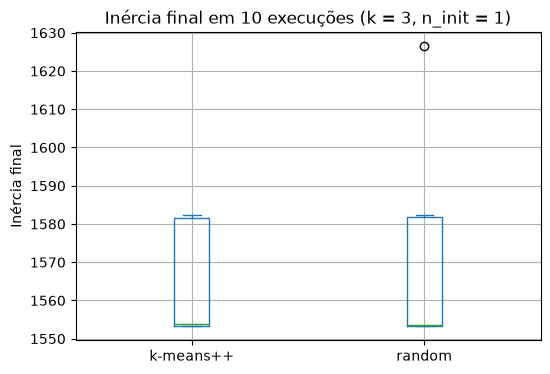

In [15]:
tabela_init.plot(kind="box", figsize=(6, 4))
plt.ylabel("Inércia final")
plt.title(f"Inércia final em 10 execuções (k = {K}, n_init = 1)")
plt.grid()
plt.savefig(f"{pasta_resultados}/inicializacao.png", dpi=150)
plt.show()

## 5. Tarefa 5 - Interpretação e validação dos grupos

### 5.1 Modelo final e centróides na escala original

In [16]:
modelo = KMeans(n_clusters=K, n_init=10, random_state=42)
grupos = modelo.fit_predict(X)

centroides_log = scaler.inverse_transform(modelo.cluster_centers_)   # desfaz o z-score
centroides = pd.DataFrame(np.expm1(centroides_log), columns=categorias)   # desfaz o log
centroides["clientes"] = np.bincount(grupos)
centroides.round(0)

,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen,clientes
0,1095.0,5635.0,9851.0,344.0,3392.0,318.0,80
1,11287.0,7972.0,10520.0,2168.0,2762.0,1906.0,147
2,7869.0,1529.0,1985.0,1976.0,246.0,602.0,213


In [17]:
g_horeca = centroides["Grocery"].idxmin()
restantes = [g for g in centroides.index if g != g_horeca]
g_grandes = centroides.loc[restantes, "Fresh"].idxmax()
g_varejo = [g for g in restantes if g != g_grandes][0]

nomes = {
    g_horeca: "Hotéis e restaurantes",
    g_grandes: "Grandes compradores",
    g_varejo: "Mercearias e varejo",
}
centroides.index = [nomes[g] for g in centroides.index]
segmento = pd.Series(grupos).map(nomes)

centroides.round(0)

,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen,clientes
Mercearias e varejo,1095.0,5635.0,9851.0,344.0,3392.0,318.0,80
Grandes compradores,11287.0,7972.0,10520.0,2168.0,2762.0,1906.0,147
Hotéis e restaurantes,7869.0,1529.0,1985.0,1976.0,246.0,602.0,213


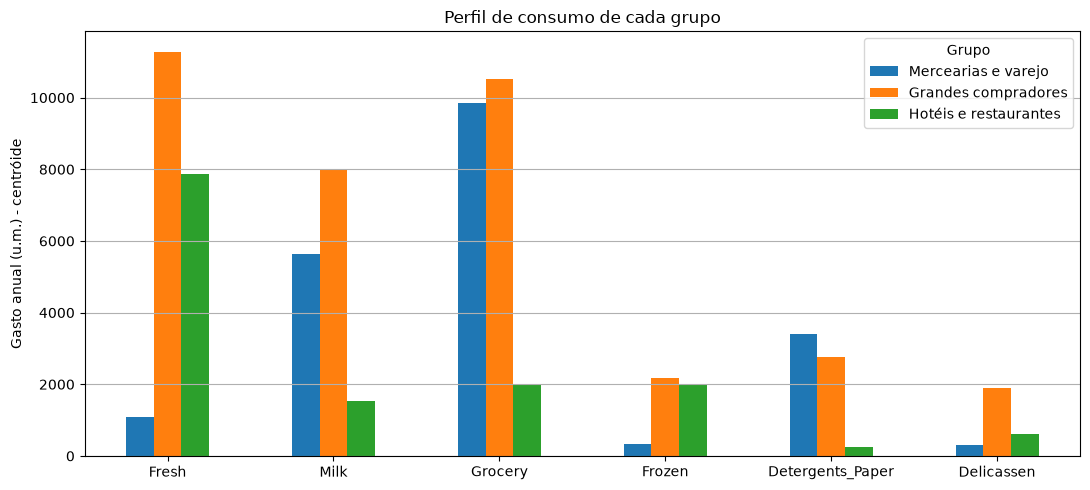

In [18]:
centroides[categorias].T.plot(kind="bar", figsize=(11, 5))
plt.ylabel("Gasto anual (u.m.) - centróide")
plt.title("Perfil de consumo de cada grupo")
plt.xticks(rotation=0)
plt.grid(axis="y")
plt.legend(title="Grupo")
plt.tight_layout()
plt.savefig(f"{pasta_resultados}/centroides_barras.png", dpi=150)
plt.show()

### 5.2 Validação externa: os grupos têm relação com `Channel` e `Region`?

In [19]:
print("Grupo x Channel")
print(pd.crosstab(segmento, canal, margins=True, margins_name="Total"))
print()
print("Grupo x Region")
print(pd.crosstab(segmento, regiao, margins=True, margins_name="Total"))

Grupo x Channel
Channel                Horeca  Retail  Total
row_0                                       
Grandes compradores        56      91    147
Hotéis e restaurantes     210       3    213
Mercearias e varejo        32      48     80
Total                     298     142    440

Grupo x Region
Region                 Lisboa  Outras  Porto  Total
row_0                                              
Grandes compradores        23     113     11    147
Hotéis e restaurantes      40     147     26    213
Mercearias e varejo        14      56     10     80
Total                      77     316     47    440


In [20]:
ari = adjusted_rand_score(canal, grupos)
print(f"ARI entre os {K} grupos e o Channel: {ari:.4f}")

# Para comparação: com k = 2 (o mesmo número de categorias do Channel)
grupos_k2 = KMeans(n_clusters=2, n_init=10, random_state=42).fit_predict(X)
print(f"ARI com k = 2 (comparação):       {adjusted_rand_score(canal, grupos_k2):.4f}")
print()
print("Grupos de k = 2 x Channel:")
print(pd.crosstab(grupos_k2, canal))

print(f"\nARI entre os {K} grupos e a Region: {adjusted_rand_score(regiao, grupos):.4f}")

ARI entre os 3 grupos e o Channel: 0.3504
ARI com k = 2 (comparação):       0.5135

Grupos de k = 2 x Channel:
Channel  Horeca  Retail
row_0                  
0           244       8
1            54     134

ARI entre os 3 grupos e a Region: -0.0064


In [21]:
# Média de gasto em cada canal: quais categorias mais separam Horeca de Retail?
media_canal = gastos.groupby(canal).mean().T
media_canal["Retail / Horeca"] = media_canal["Retail"] / media_canal["Horeca"]
media_canal.round({"Horeca": 0, "Retail": 0, "Retail / Horeca": 2})

Channel,Horeca,Retail,Retail / Horeca
Fresh,13476.0,8904.0,0.66
Milk,3452.0,10716.0,3.10
Grocery,3962.0,16323.0,4.12
Frozen,3748.0,1653.0,0.44
Detergents_Paper,791.0,7270.0,9.20
Delicassen,1416.0,1753.0,1.24


### 5.3 Visualização em duas dimensões (PCA)

Variância explicada pelas 2 componentes: 71.3%


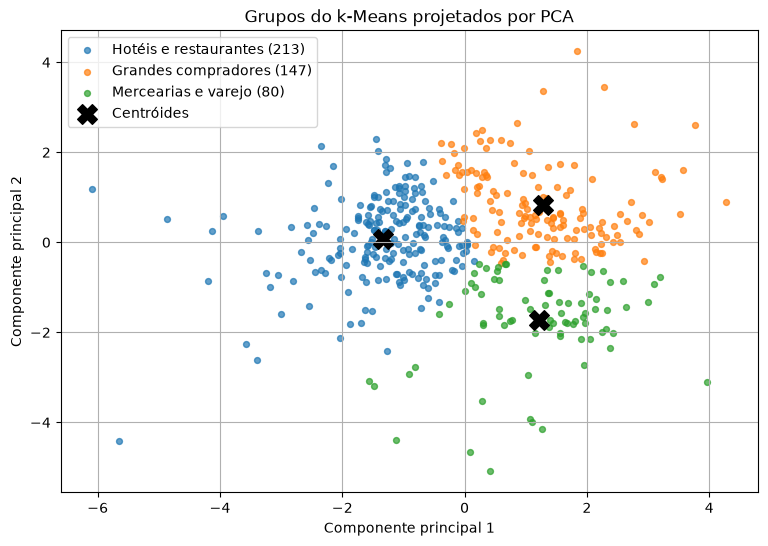

In [22]:
pca = PCA(n_components=2)
X_2d = pca.fit_transform(X)
print(f"Variância explicada pelas 2 componentes: {pca.explained_variance_ratio_.sum():.1%}")

centros_2d = pca.transform(modelo.cluster_centers_)

plt.figure(figsize=(9, 6))
for g, nome in nomes.items():
    pontos = X_2d[grupos == g]
    plt.scatter(pontos[:, 0], pontos[:, 1], s=18, alpha=0.7, label=f"{nome} ({len(pontos)})")
plt.scatter(centros_2d[:, 0], centros_2d[:, 1], c="black", marker="X", s=200, label="Centróides")
plt.xlabel("Componente principal 1")
plt.ylabel("Componente principal 2")
plt.title("Grupos do k-Means projetados por PCA")
plt.legend()
plt.grid()
plt.savefig(f"{pasta_resultados}/pca_grupos.png", dpi=150)
plt.show()